In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Numerical Parameterisation of DVM

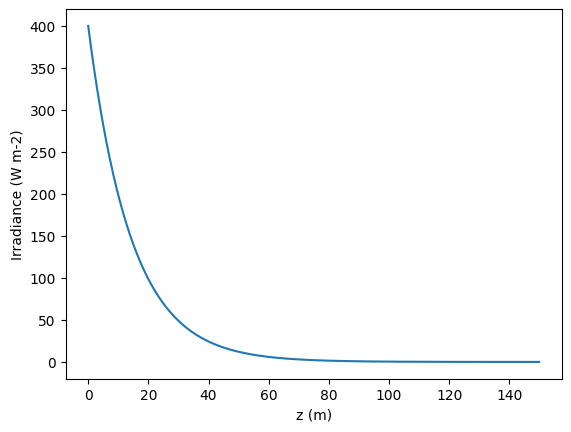

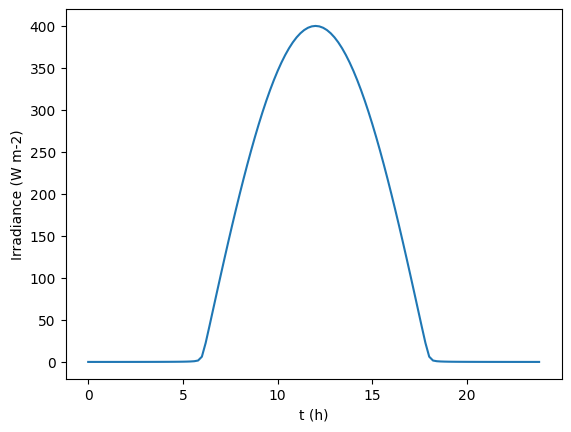

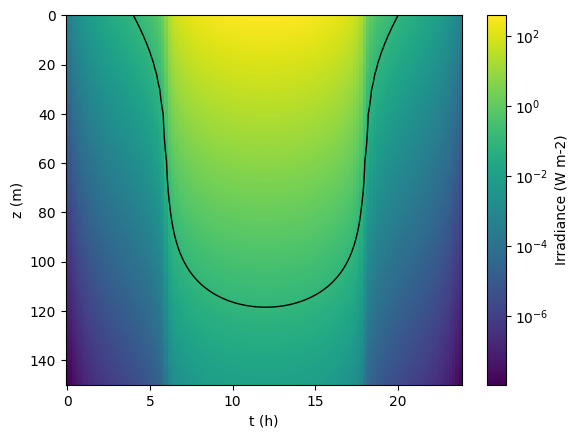

In [2]:
# Richards 1996 Model for Light Intensity / Variation
I_surf = 400.0 # W m-2
I_s = 1.0e-6 #(at midnight)
eps = 1.0e-3
a = 0.07 # m-1

def tau(t): # in hours
    return I_s + 0.5*(1.0-I_s)*(1.0+np.sin(np.pi/12.0*(t-6.0)) + np.sqrt(eps+np.sin(np.pi/12.0*(t-6.0))**2) - np.sqrt(eps+1.0))

def zeta(z):
    return np.exp(-a*z)

def I_irr(z,t):
    return I_surf * tau(t) * zeta(z)

z = np.arange(0, 150, 0.1)
t = np.arange(0, 24, 0.2)

# Plot I_irr vs z
plt.figure()
plt.plot(z,I_irr(z,12))
#plt.yscale("log")
plt.xlabel("z (m)")
plt.ylabel("Irradiance (W m-2)")

# Plot I_irr vs t
plt.figure()
plt.plot(t,I_irr(0,t))
plt.xlabel("t (h)")
plt.ylabel("Irradiance (W m-2)")

# Create a 3D surface plot of I_irr as a function of z and t
Z, T = np.meshgrid(z, t)
plt.figure()
plt.pcolor(T, Z, I_irr(Z, T), norm=mcolors.LogNorm())
plt.gca().invert_yaxis()  # Flip the y-axis
plt.ylabel('z (m)')
plt.xlabel('t (h)')
plt.colorbar(label='Irradiance (W m-2)', norm=mcolors.LogNorm())
plt.contour(T, Z, I_irr(Z, T), levels=[1e-1], colors='k', linewidths=1)


# COBALTv2 New DVM Model

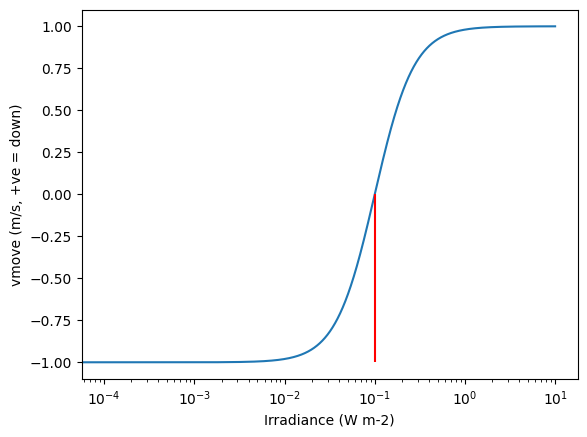

In [35]:
swim_max = 0.025 # m s-1
dvm_I_thresh = 0.1 # W m-2
#k_I_dvm = 0.1 # W m-2
eps = 1.0e-30

def vmove_model(I):
    return swim_max * np.tanh(np.log((I + eps)/dvm_I_thresh))


irr_inst = np.arange(0, 10, 0.0001) # W m-2
vmove = np.zeros(len(irr_inst))

vmove = vmove_model(irr_inst)

plt.plot(irr_inst, vmove/swim_max)
plt.vlines(dvm_I_thresh,-1,0,'r')
plt.ylabel("vmove (m/s, +ve = down)")
plt.xlabel("Irradiance (W m-2)")
plt.xscale("log")

In [36]:
t_end = 24.0*3600.0 # s
dt = 60.0 # s
Nt = int(t_end / dt)

z_0 = np.arange(20,21,1)

z_zoo = np.zeros((Nt, len(z_0)))
z_zoo[0,:] = z_0

t = np.arange(0,t_end,dt)

for i in range(Nt-1):
    for j in range(len(z_0)):
        v = vmove_model(I_irr(z_zoo[i,j],t[i]/3600.0))
        z_zoo[i+1,j] = max(z_zoo[i,j] + v*dt, 0.0)


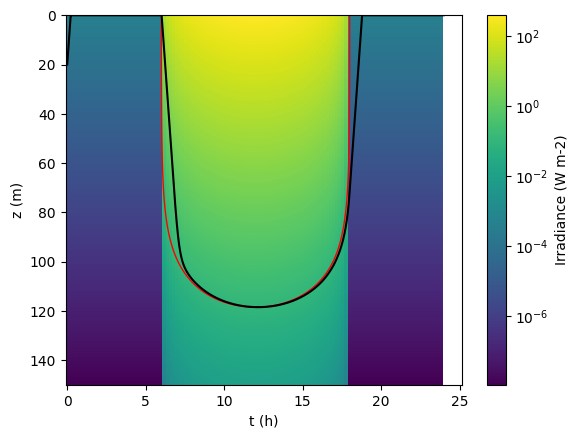

In [37]:
zc = np.arange(0, 150, 0.1)
tc = np.arange(0, 24, 0.2)
Zc, Tc = np.meshgrid(zc, tc)
plt.figure()
plt.pcolor(Tc, Zc, I_irr(Zc, Tc), norm=mcolors.LogNorm())
plt.gca().invert_yaxis()  # Flip the y-axis
plt.ylabel('z (m)')
plt.xlabel('t (h)')
plt.colorbar(label='Irradiance (W m-2)', norm=mcolors.LogNorm())

plt.contour(Tc, Zc, I_irr(Zc, Tc), levels=[1e-1], colors='r', linewidths=1)

plt.plot(t/3600, z_zoo, 'k')
